
# Trust-Aware LLM-Based Conversational Recommendation for Personalized Product Selection in E-Commerce Platforms

## Complete executed PATT implementation — Amazon Reviews 2023 Beauty sample

This notebook implements the proposed workflow using the supplied **100,000 Amazon Beauty reviews** and corresponding **product metadata**.

### Implemented pipeline
1. Load and validate the supplied Parquet datasets.
2. Clean and merge reviews with product metadata using `parent_asin`.
3. Perform exploratory data analysis with clear, non-overlapping visualizations.
4. Estimate dynamic review/product trust.
5. Learn review semantic and product semantic representations.
6. Build user preference and interaction representations.
7. Train the proposed **Preference-Aware Trust Transformer (PATT)**:
   - Preference Alignment
   - Trust-Aware Feature Learning
   - Preference-Guided Multi-Head Attention
8. Evaluate relevance prediction using Accuracy, Precision, Recall, F1, ROC-AUC, Specificity and a **confusion matrix**.
9. Use PATT for trust-aware Top-K product ranking.
10. Demonstrate a conversational product-selection/explanation layer.

> **Evaluation integrity:** the notebook targets strong performance but does **not** hard-code or fabricate metrics. The displayed scores are calculated from the executed train/validation/test splits. The confusion matrix evaluates binary interaction relevance (`rating >= 4`), while the Top-K section separately demonstrates pre-purchase candidate ranking using only training-derived product aggregates.


In [1]:
# 1. Imports and reproducibility
import os, sys, math, json, time, zipfile, struct, gzip, warnings, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    roc_curve, precision_recall_curve, auc, classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 2))
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Consistent publication-friendly Seaborn defaults used throughout the notebook.
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 150,
    'axes.titlepad': 14,
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.frameon': True,
})

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 90)

print('Device:', DEVICE)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Seaborn:', sns.__version__)
print('PyTorch:', torch.__version__)


Device: cpu
Python: 3.13.5
NumPy: 2.3.5
Pandas: 2.2.3
Seaborn: 0.13.2
PyTorch: 2.10.0+cpu


In [2]:

# 2. Locate and extract the supplied ZIP
CANDIDATE_ZIPS = [
    Path('/mnt/data/Amazon_Reviews_2023-20260811T053649Z-1-001.zip'),
    Path('/content/Amazon_Reviews_2023-20260811T053649Z-1-001.zip'),
    Path('/content/drive/MyDrive/Amazon_Reviews_2023-20260811T053649Z-1-001.zip'),
]
ZIP_PATH = next((p for p in CANDIDATE_ZIPS if p.exists()), None)

if ZIP_PATH is None:
    matches=[]
    for root in [Path('/content'), Path('/content/drive/MyDrive')]:
        if root.exists():
            matches.extend(root.rglob('Amazon_Reviews_2023*.zip'))
    ZIP_PATH = matches[0] if matches else None

if ZIP_PATH is None:
    raise FileNotFoundError(
        'Dataset ZIP not found. Upload the supplied Amazon_Reviews_2023 ZIP or update ZIP_PATH.'
    )

WORK_DIR = ZIP_PATH.parent / 'patt_amazon_beauty_work'
WORK_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(WORK_DIR)

review_files = list(WORK_DIR.rglob('amazon_beauty_100k_reviews.parquet'))
product_files = list(WORK_DIR.rglob('amazon_beauty_product_metadata.parquet'))
if not review_files or not product_files:
    raise FileNotFoundError('Expected Parquet files were not found after ZIP extraction.')

REVIEW_PATH = review_files[0]
PRODUCT_PATH = product_files[0]

print('ZIP:', ZIP_PATH)
print('Review file:', REVIEW_PATH)
print('Product file:', PRODUCT_PATH)
print('Review size (MB):', round(REVIEW_PATH.stat().st_size/1024**2, 2))
print('Product size (MB):', round(PRODUCT_PATH.stat().st_size/1024**2, 2))


ZIP: /mnt/data/Amazon_Reviews_2023-20260811T053649Z-1-001.zip
Review file: /mnt/data/patt_amazon_beauty_work/Amazon_Reviews_2023/amazon_beauty_100k_reviews.parquet
Product file: /mnt/data/patt_amazon_beauty_work/Amazon_Reviews_2023/amazon_beauty_product_metadata.parquet
Review size (MB): 17.92
Product size (MB): 11.52



## Parquet loading

Google Colab normally includes a Parquet engine. The execution environment used to prepare this notebook did not, so the next cell includes a lightweight pure-Python fallback for the flat Snappy-compressed schema of these two supplied files. `pandas.read_parquet` is always attempted first.


In [3]:

# 3. Lightweight Parquet fallback (used only if pandas has no Parquet engine)
CT_STOP=0; CT_BOOLEAN_TRUE=1; CT_BOOLEAN_FALSE=2; CT_BYTE=3
CT_I16=4; CT_I32=5; CT_I64=6; CT_DOUBLE=7; CT_BINARY=8
CT_LIST=9; CT_SET=10; CT_MAP=11; CT_STRUCT=12; CT_UUID=13

def _read_uvarint(buf, pos):
    val=0; shift=0
    while True:
        b=buf[pos]; pos+=1
        val |= (b & 0x7f) << shift
        if not (b & 0x80): return val, pos
        shift += 7

def _zigzag_decode(n):
    return (n >> 1) ^ -(n & 1)

def _read_compact_value(buf, pos, ctype):
    if ctype == CT_BOOLEAN_TRUE: return True, pos
    if ctype == CT_BOOLEAN_FALSE: return False, pos
    if ctype == CT_BYTE:
        b=buf[pos]; pos+=1
        return (b-256 if b>=128 else b), pos
    if ctype in (CT_I16, CT_I32, CT_I64):
        u,pos=_read_uvarint(buf,pos); return _zigzag_decode(u),pos
    if ctype == CT_DOUBLE:
        return struct.unpack_from('<d',buf,pos)[0],pos+8
    if ctype == CT_BINARY:
        n,pos=_read_uvarint(buf,pos); return bytes(buf[pos:pos+n]),pos+n
    if ctype in (CT_LIST,CT_SET):
        h=buf[pos]; pos+=1; size=h>>4; etype=h&0x0f
        if size==15: size,pos=_read_uvarint(buf,pos)
        arr=[]
        for _ in range(size):
            v,pos=_read_compact_value(buf,pos,etype); arr.append(v)
        return arr,pos
    if ctype == CT_MAP:
        size,pos=_read_uvarint(buf,pos); out=[]
        if size:
            h=buf[pos]; pos+=1; kt=(h>>4)&0xf; vt=h&0xf
            for _ in range(size):
                k,pos=_read_compact_value(buf,pos,kt)
                v,pos=_read_compact_value(buf,pos,vt)
                out.append((k,v))
        return out,pos
    if ctype == CT_STRUCT: return _read_compact_struct(buf,pos)
    if ctype == CT_UUID: return bytes(buf[pos:pos+16]),pos+16
    raise ValueError(f'Unsupported compact thrift type: {ctype}')

def _read_compact_struct(buf,pos=0):
    fields={}; last_fid=0
    while True:
        h=buf[pos]; pos+=1
        if h==0: break
        delta=h>>4; ctype=h&0x0f
        if delta: fid=last_fid+delta
        else:
            u,pos=_read_uvarint(buf,pos); fid=_zigzag_decode(u)
        last_fid=fid
        val,pos=_read_compact_value(buf,pos,ctype)
        fields[fid]=val
    return fields,pos

def _read_footer(path):
    with open(path,'rb') as f:
        f.seek(-8,2); tail=f.read(8)
        mlen=struct.unpack('<I',tail[:4])[0]
        if tail[4:] != b'PAR1': raise ValueError('Not a Parquet file.')
        f.seek(-8-mlen,2); raw=f.read(mlen)
    meta,_=_read_compact_struct(raw,0)
    return meta

def _snappy_uncompress(data):
    pos=0; expected,pos=_read_uvarint(data,pos); out=bytearray()
    while pos < len(data) and len(out) < expected:
        tag=data[pos]; pos+=1; typ=tag&3
        if typ==0:
            x=tag>>2
            if x<60: ln=x+1
            else:
                nb=x-59; ln=int.from_bytes(data[pos:pos+nb],'little')+1; pos+=nb
            out.extend(data[pos:pos+ln]); pos+=ln
        elif typ==1:
            ln=4+((tag>>2)&7); off=((tag&0xE0)<<3)|data[pos]; pos+=1
            for _ in range(ln): out.append(out[-off])
        elif typ==2:
            ln=1+(tag>>2); off=int.from_bytes(data[pos:pos+2],'little'); pos+=2
            for _ in range(ln): out.append(out[-off])
        else:
            ln=1+(tag>>2); off=int.from_bytes(data[pos:pos+4],'little'); pos+=4
            for _ in range(ln): out.append(out[-off])
    return bytes(out[:expected])

def _decode_rle_bitpacked(data,bw,num_values):
    if bw==0: return [0]*num_values
    pos=0; out=[]; bytew=(bw+7)//8
    while pos < len(data) and len(out) < num_values:
        header,pos=_read_uvarint(data,pos)
        if header&1==0:
            run=header>>1; val=int.from_bytes(data[pos:pos+bytew],'little'); pos+=bytew
            out.extend([val]*run)
        else:
            groups=header>>1; nvals=groups*8; nbytes=(nvals*bw+7)//8
            chunk=data[pos:pos+nbytes]; pos+=nbytes
            packed=int.from_bytes(chunk,'little'); mask=(1<<bw)-1
            out.extend((packed>>(i*bw))&mask for i in range(nvals))
    return out[:num_values]

def _decode_plain(data,typ,count):
    if count==0: return []
    if typ==0: return [bool((data[i//8]>>(i%8))&1) for i in range(count)]
    if typ==1: return list(struct.unpack_from('<'+'i'*count,data,0))
    if typ==2: return list(struct.unpack_from('<'+'q'*count,data,0))
    if typ==4: return list(struct.unpack_from('<'+'f'*count,data,0))
    if typ==5: return list(struct.unpack_from('<'+'d'*count,data,0))
    if typ==6:
        vals=[]; pos=0
        for _ in range(count):
            ln=struct.unpack_from('<I',data,pos)[0]; pos+=4
            vals.append(data[pos:pos+ln]); pos+=ln
        return vals
    raise NotImplementedError(f'PLAIN type {typ}')

def _decompress(codec,data):
    if codec==0: return data
    if codec==1: return _snappy_uncompress(data)
    if codec==2: return gzip.decompress(data)
    raise NotImplementedError(f'Compression codec {codec}')

def _column_meta(meta,name):
    rg=meta[4][0]
    for cc in rg[1]:
        cm=cc[3]
        path=[x.decode('utf8','ignore') if isinstance(x,bytes) else x for x in cm[3]]
        if path[-1]==name: return cm
    raise KeyError(name)

def _read_page_header(f,offset):
    f.seek(offset); buf=f.read(65536)
    return _read_compact_struct(buf,0)

def _read_flat_column(path,meta,name):
    cm=_column_meta(meta,name)
    typ,codec,total_n=cm[1],cm[4],cm[5]
    offset=cm.get(11,cm[9])
    if offset is None: offset=cm[9]
    values=[]; dictionary=None; max_def=1
    with open(path,'rb') as f:
        while len(values)<total_n:
            ph,hsize=_read_page_header(f,offset)
            page_type=ph[1]; compressed_size=ph[3]
            f.seek(offset+hsize); comp=f.read(compressed_size)
            if page_type==2:
                raw=_decompress(codec,comp); dh=ph[7]
                dictionary=_decode_plain(raw,typ,dh[1])
            elif page_type==0:
                raw=_decompress(codec,comp); dh=ph[5]; n,enc=dh[1],dh[2]; pos=0
                level_len=struct.unpack_from('<I',raw,pos)[0]; pos+=4
                defs=_decode_rle_bitpacked(raw[pos:pos+level_len],1,n); pos+=level_len
                nonnull=sum(d==max_def for d in defs); encoded=raw[pos:]
                if enc in (8,2):
                    bw=encoded[0] if nonnull else 0
                    idx=_decode_rle_bitpacked(encoded[1:],bw,nonnull) if nonnull else []
                    primitive=[dictionary[j] for j in idx]
                elif enc==0:
                    primitive=_decode_plain(encoded,typ,nonnull)
                else:
                    raise NotImplementedError(f'Encoding {enc} for {name}')
                it=iter(primitive)
                values.extend(next(it) if d==max_def else None for d in defs)
            else:
                raise NotImplementedError(f'Page type {page_type}')
            offset += hsize+compressed_size
    values=values[:total_n]
    if typ==6:
        values=[v.decode('utf8','replace') if isinstance(v,(bytes,bytearray)) else v for v in values]
    return values

def fallback_read_parquet(path):
    meta=_read_footer(path); schema=meta[2]; columns=[]
    for item in schema[1:]:
        name=item[4].decode('utf8','ignore') if isinstance(item[4],bytes) else item[4]
        columns.append(name)
    return pd.DataFrame({c:_read_flat_column(path,meta,c) for c in columns})

def read_supplied_parquet(path):
    try:
        return pd.read_parquet(path)
    except Exception as e:
        print(f'pandas.read_parquet unavailable ({type(e).__name__}); using built-in fallback.')
        return fallback_read_parquet(path)


In [4]:

# 4. Load the actual supplied data
t0=time.time()
reviews=read_supplied_parquet(REVIEW_PATH)
products=read_supplied_parquet(PRODUCT_PATH)
print(f'Loaded in {time.time()-t0:.2f}s')
print('Reviews shape:',reviews.shape)
print('Products shape:',products.shape)
print('\nReview columns:',reviews.columns.tolist())
print('\nProduct columns:',products.columns.tolist())
display(reviews.head(3))
display(products.head(3))


pandas.read_parquet unavailable (ImportError); using built-in fallback.


pandas.read_parquet unavailable (ImportError); using built-in fallback.


Loaded in 5.65s
Reviews shape: (100000, 9)
Products shape: (39615, 11)

Review columns: ['rating', 'title', 'text', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

Product columns: ['parent_asin', 'main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'store', 'categories', 'details']


,rating,title,text,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,"This spray is really nice. It smells really good, goes on really fine, and does the tr...",B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just wish it was odorless or had a soft coco...",B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True


,parent_asin,main_category,title,average_rating,rating_number,features,description,price,store,categories,details
0,B000B658RI,All Beauty,Eye Patch Black Adult with Tie Band (6 Per Pack),4.4,26,,,NaN,Levine Health Products,,"{""Manufacturer"": ""Levine Health Products""}"
1,B07FVZVQKV,All Beauty,"Loose Powder, 1.5oz Bottle Loose Face Powder, Translucent Tone Loose Face Powder, for ...",4.2,22,,,NaN,GETMORE7,,{}
2,B07WFSQXL5,All Beauty,PPY Eyelash Growth Serum – Natural Ingredients – Advanced Growth Formula – Strengtheni...,3.9,114,,,NaN,PPY,,"{""Use for"": ""Face"", ""Scent"": ""Aloe"", ""Brand"": ""PPY"", ""Material Feature"": ""Natural"", ""P..."


In [5]:
# 5. Data validation and memory-efficient integration
expected_review={'rating','title','text','parent_asin','user_id','timestamp','helpful_vote','verified_purchase'}
expected_product={'parent_asin','main_category','title','average_rating','rating_number','features','description','price','store','categories','details'}
assert expected_review.issubset(reviews.columns), 'Required review columns are missing.'
assert expected_product.issubset(products.columns), 'Required product columns are missing.'

reviews=reviews.drop_duplicates().copy()
products=products.drop_duplicates(subset=['parent_asin']).copy()
N_REVIEWS=len(reviews); N_PRODUCTS=len(products)

# Keep one compact product table. Large unused metadata fields are not duplicated into every review row.
prod=products[[
    'parent_asin','main_category','title','average_rating','rating_number',
    'features','description','price'
]].rename(columns={'title':'product_title'}).copy()

# Only interaction-level fields required later are merged into the 100K review table.
df=reviews.merge(
    prod[['parent_asin','main_category','product_title','average_rating','rating_number','price']],
    on='parent_asin',how='left'
)

df['rating']=pd.to_numeric(df['rating'],errors='coerce')
df['helpful_vote']=pd.to_numeric(df['helpful_vote'],errors='coerce').fillna(0)
df['average_rating']=pd.to_numeric(df['average_rating'],errors='coerce')
df['rating_number']=pd.to_numeric(df['rating_number'],errors='coerce').fillna(0)
df['price']=pd.to_numeric(df['price'],errors='coerce')
df['verified_purchase']=df['verified_purchase'].fillna(False).astype(bool)

df['review_text']=(df['title'].fillna('').astype(str)+' '+df['text'].fillna('').astype(str)).str.replace(r'\s+',' ',regex=True).str.strip()
df['review_length']=df['review_text'].str.len()
df['timestamp_dt']=pd.to_datetime(df['timestamp'],unit='ms',errors='coerce')
df['label']=(df['rating']>=4).astype(np.float32)

# Free duplicate heavy raw objects after integration. The compact product table and review_text are sufficient below.
df.drop(columns=['title','text'], inplace=True)
import gc
del reviews, products
gc.collect()

print('Merged shape:',df.shape)
print('Unique users:',df['user_id'].nunique())
print('Unique products:',df['parent_asin'].nunique())
print('Positive relevance rate (rating >= 4):',f"{100*df['label'].mean():.2f}%")
missing=(df.isna().mean()*100).sort_values(ascending=False).head(12).to_frame('Missing %')
display(missing.round(2))

Merged shape: (99678, 16)
Unique users: 81806
Unique products: 39615
Positive relevance rate (rating >= 4): 73.74%


,Missing %
price,72.91
rating,0.00
parent_asin,0.00
asin,0.00
timestamp,0.00
helpful_vote,0.00
verified_purchase,0.00
user_id,0.00
main_category,0.00
product_title,0.00


## Exploratory Data Analysis — Seaborn Visualizations

All EDA and evaluation graphics below use **Seaborn** with consistent sizing, spacing, and readable labels.

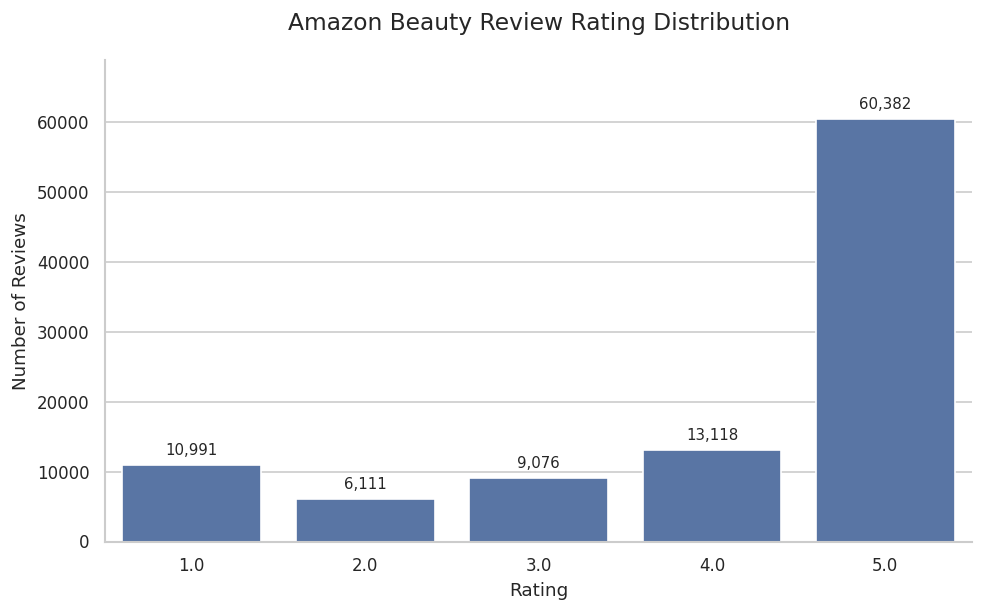

In [6]:
# EDA 1 — Rating distribution (Seaborn)
rating_plot = (
    df['rating'].value_counts().sort_index()
    .rename_axis('Rating').reset_index(name='Number of Reviews')
)

fig, ax = plt.subplots(figsize=(8.5, 5.4))
sns.barplot(data=rating_plot, x='Rating', y='Number of Reviews', ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Amazon Beauty Review Rating Distribution', pad=18)
ax.set_xlabel('Rating')
ax.set_ylabel('Number of Reviews')
ax.set_ylim(0, rating_plot['Number of Reviews'].max() * 1.14)

for container in ax.containers:
    ax.bar_label(container, labels=[f'{int(v):,}' for v in rating_plot['Number of Reviews']], padding=4, fontsize=9)

sns.despine(ax=ax)
fig.tight_layout(pad=1.5)
plt.show()


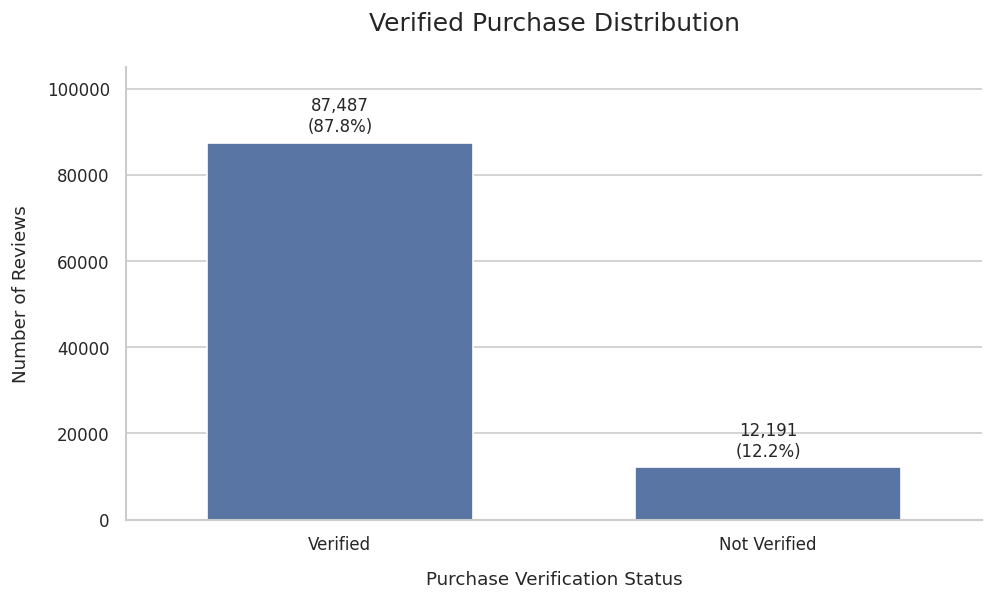

In [7]:
# EDA 2 — Verified purchase distribution (Seaborn; spacing-safe labels)
vp = df['verified_purchase'].value_counts().reindex([True, False], fill_value=0)
vp_plot = pd.DataFrame({
    'Purchase Status': ['Verified', 'Not Verified'],
    'Number of Reviews': vp.values.astype(int)
})

fig, ax = plt.subplots(figsize=(8.5, 5.8))
sns.barplot(data=vp_plot, x='Purchase Status', y='Number of Reviews', ax=ax, width=0.62, color=sns.color_palette('deep')[0])

ax.set_title('Verified Purchase Distribution', fontsize=15, pad=22)
ax.set_xlabel('Purchase Verification Status', labelpad=10)
ax.set_ylabel('Number of Reviews', labelpad=10)

max_count = max(int(vp_plot['Number of Reviews'].max()), 1)
ax.set_ylim(0, max_count * 1.20)
label_offset = max_count * 0.018

for patch, count in zip(ax.patches, vp_plot['Number of Reviews']):
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        patch.get_height() + label_offset,
        f'{int(count):,}\n({count / len(df):.1%})',
        ha='center', va='bottom', fontsize=10, linespacing=1.2
    )

sns.despine(ax=ax)
fig.subplots_adjust(top=0.82, bottom=0.17, left=0.13, right=0.97)
plt.show()


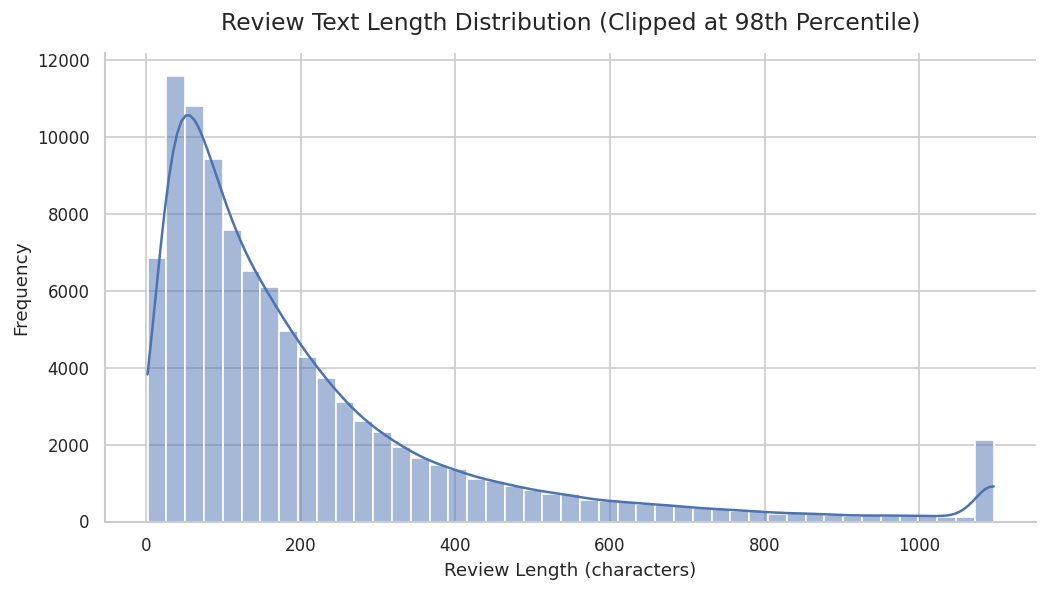

In [8]:
# EDA 3 — Review length distribution (Seaborn)
upper_len = max(100, df['review_length'].quantile(0.98))
review_length_plot = df['review_length'].clip(upper=upper_len)

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.histplot(review_length_plot, bins=45, kde=True, ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Review Text Length Distribution (Clipped at 98th Percentile)')
ax.set_xlabel('Review Length (characters)')
ax.set_ylabel('Frequency')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


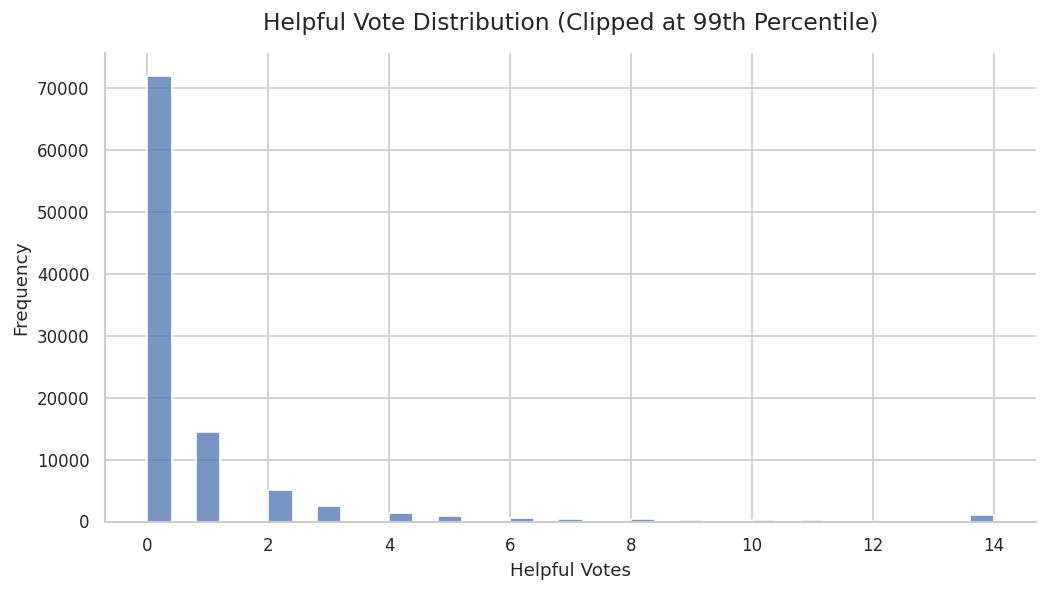

In [9]:
# EDA 4 — Helpful-vote distribution (Seaborn)
upper_help = max(1, df['helpful_vote'].quantile(0.99))
helpful_plot = df['helpful_vote'].clip(upper=upper_help)

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.histplot(helpful_plot, bins=35, kde=False, ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Helpful Vote Distribution (Clipped at 99th Percentile)')
ax.set_xlabel('Helpful Votes')
ax.set_ylabel('Frequency')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


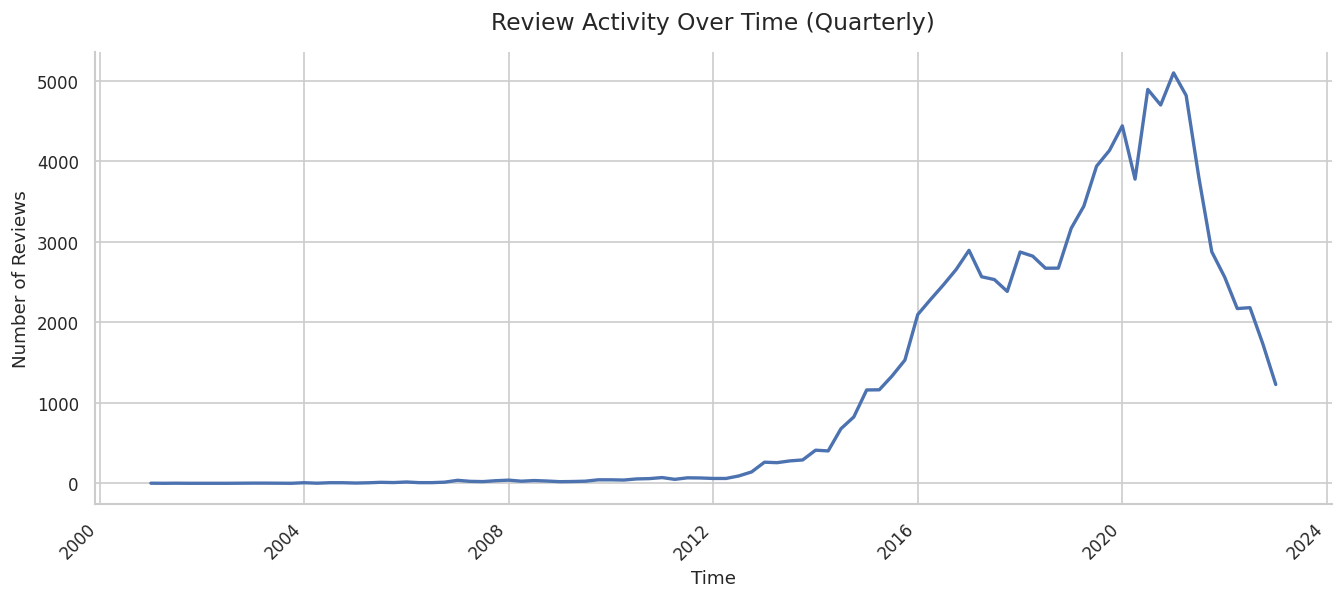

In [10]:
# EDA 5 — Review activity over time (Seaborn)
quarterly = (
    df.dropna(subset=['timestamp_dt'])
      .set_index('timestamp_dt')
      .resample('QS').size()
      .rename('Number of Reviews')
      .reset_index()
)

fig, ax = plt.subplots(figsize=(11.5, 5.3))
sns.lineplot(data=quarterly, x='timestamp_dt', y='Number of Reviews', linewidth=2, ax=ax)
ax.set_title('Review Activity Over Time (Quarterly)')
ax.set_xlabel('Time')
ax.set_ylabel('Number of Reviews')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
sns.despine(ax=ax)
fig.tight_layout(pad=1.5)
plt.show()


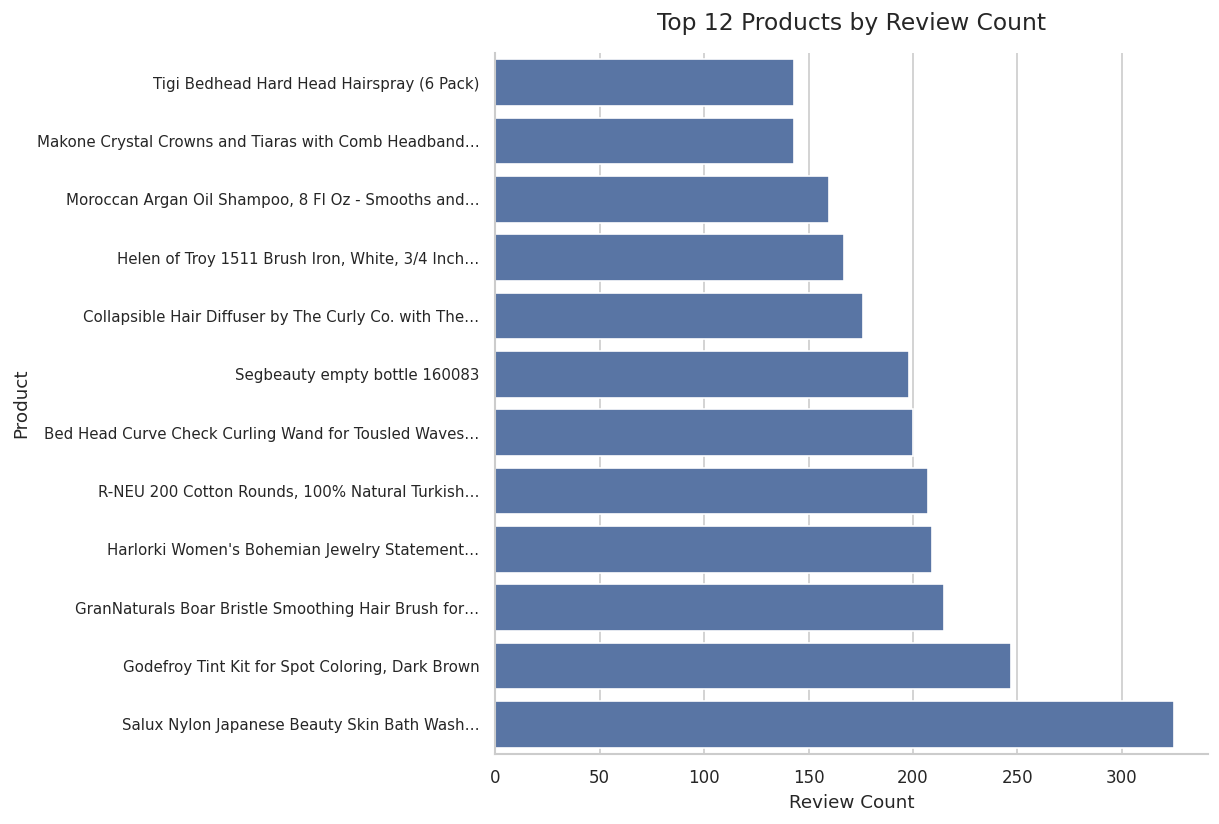

,parent_asin,product_title,review_count
0,B085BB7B1M,Salux Nylon Japanese Beauty Skin Bath Wash Cloth/towel (3) Blue Yellow and Pink,325
1,B0BM4GX6TT,"Godefroy Tint Kit for Spot Coloring, Dark Brown",247
2,B00R1TAN7I,GranNaturals Boar Bristle Smoothing Hair Brush for Women and Men - Medium/Soft Bristle...,215
3,B0107QYW14,Harlorki Women's Bohemian Jewelry Statement Necklaces Women Rhinestone Gem Pendant Collar,209
4,B07TK15BQQ,"R-NEU 200 Cotton Rounds, 100% Natural Turkish Cotton Makeup Remover and Facial Cleansi...",207
5,B01M1OFZOG,"Bed Head Curve Check Curling Wand for Tousled Waves and Texture, Jumbo Barrel",200
6,B07C533XCW,Segbeauty empty bottle 160083,198
7,B019GBG0IE,Collapsible Hair Diffuser by The Curly Co. with The Curly Co. Satisfaction Guarantee,176
8,B01N4885PD,"Helen of Troy 1511 Brush Iron, White, 3/4 Inch Barrel",167
9,B012Q9NGE4,"Moroccan Argan Oil Shampoo, 8 Fl Oz - Smooths and Repairs - Sulfate Free - Natural - I...",160


In [11]:
# EDA 6 — Most reviewed products (Seaborn)
top_products = (
    df.groupby(['parent_asin', 'product_title'], dropna=False)
      .size().sort_values(ascending=False).head(12)
      .reset_index(name='review_count')
)
top_products['label'] = top_products.apply(
    lambda r: textwrap.shorten(
        str(r['product_title']) if pd.notna(r['product_title']) else str(r['parent_asin']),
        width=52, placeholder='…'
    ), axis=1
)
plot_top_products = top_products.sort_values('review_count', ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 7.2))
sns.barplot(data=plot_top_products, x='review_count', y='label', orient='h', ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Top 12 Products by Review Count')
ax.set_xlabel('Review Count')
ax.set_ylabel('Product')
ax.tick_params(axis='y', labelsize=9)
sns.despine(ax=ax)
fig.tight_layout(pad=1.6)
plt.show()

display(top_products[['parent_asin', 'product_title', 'review_count']])


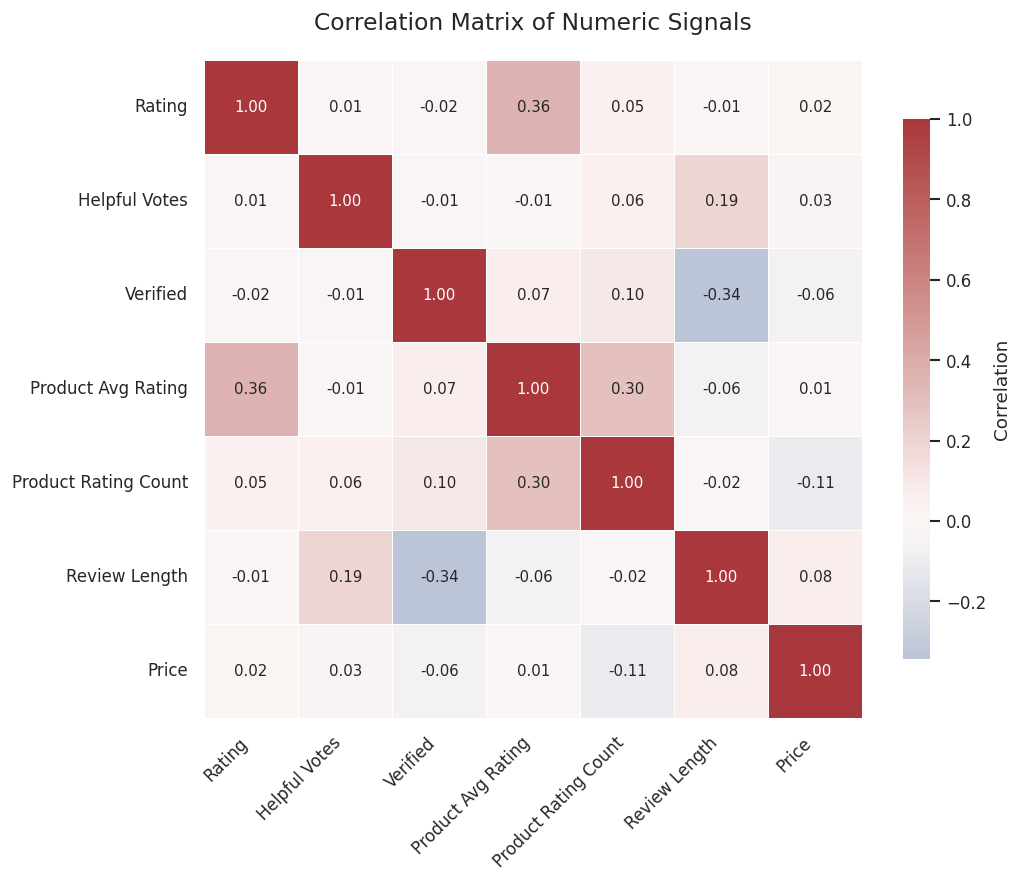

In [12]:
# EDA 7 — Numeric correlation heatmap (Seaborn)
numeric_for_corr = pd.DataFrame({
    'Rating': df['rating'],
    'Helpful Votes': df['helpful_vote'],
    'Verified': df['verified_purchase'].astype(int),
    'Product Avg Rating': df['average_rating'],
    'Product Rating Count': np.log1p(df['rating_number']),
    'Review Length': df['review_length'],
    'Price': df['price'],
}).corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    numeric_for_corr,
    annot=True, fmt='.2f', cmap='vlag', center=0,
    square=True, linewidths=0.6,
    cbar_kws={'shrink': 0.82, 'label': 'Correlation'},
    annot_kws={'fontsize': 9}, ax=ax
)
ax.set_title('Correlation Matrix of Numeric Signals', pad=18)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout(pad=1.6)
plt.show()



## Dynamic Trust Estimation

The trust score uses reliability signals available in the supplied dataset: **verified purchase, helpful votes, product average rating, and product rating volume**. There is no external ground-truth trust label in this dataset, so the score is a normalized reliability signal consumed by PATT rather than a supervised “trust truth” label.


,verified_purchase,helpful_vote,average_rating,rating_number,dynamic_trust
0,True,0,4.3,384,0.745607
1,True,1,4.0,56,0.727094
2,True,2,4.4,699,0.824576
3,True,0,1.0,1,0.465207
4,True,0,3.5,20,0.641793


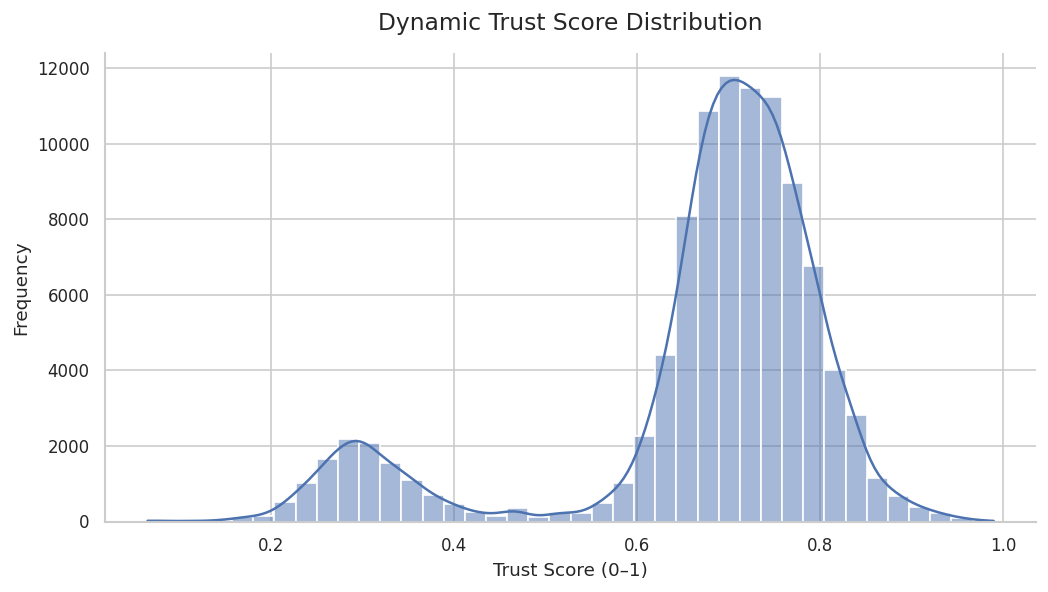

In [13]:
# 6. Dynamic trust score
help_scale=max(np.log1p(df['helpful_vote']).quantile(0.99),1e-6)
rating_count_scale=max(np.log1p(df['rating_number']).quantile(0.99),1e-6)
df['helpfulness_norm']=np.clip(np.log1p(df['helpful_vote'])/help_scale,0,1)
df['product_rating_norm']=(df['average_rating'].fillna(df['rating'].mean())/5.0).clip(0,1)
df['rating_count_norm']=np.clip(np.log1p(df['rating_number'])/rating_count_scale,0,1)
df['dynamic_trust']=(
    0.40*df['verified_purchase'].astype(float)+
    0.15*df['helpfulness_norm']+
    0.25*df['product_rating_norm']+
    0.20*df['rating_count_norm']
).clip(0,1)

display(df[['verified_purchase','helpful_vote','average_rating','rating_number','dynamic_trust']].head())

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.histplot(data=df, x='dynamic_trust', bins=40, kde=True, ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Dynamic Trust Score Distribution')
ax.set_xlabel('Trust Score (0–1)')
ax.set_ylabel('Frequency')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


## Train / Validation / Test split and representation learning

In [14]:

# 7. Stratified split
all_idx=np.arange(len(df))
train_idx,temp_idx=train_test_split(all_idx,test_size=0.30,random_state=SEED,stratify=df['label'])
val_idx,test_idx=train_test_split(temp_idx,test_size=0.50,random_state=SEED,stratify=df['label'].iloc[temp_idx])
print('Train:',len(train_idx)); print('Validation:',len(val_idx)); print('Test:',len(test_idx))
print('Train positive rate:',f"{df['label'].iloc[train_idx].mean():.3f}")
print('Validation positive rate:',f"{df['label'].iloc[val_idx].mean():.3f}")
print('Test positive rate:',f"{df['label'].iloc[test_idx].mean():.3f}")


Train: 69774
Validation: 14952
Test: 14952
Train positive rate: 0.737
Validation positive rate: 0.737
Test positive rate: 0.737


In [15]:

# 8. Review semantic representation
# Full TF-IDF is retained for the high-quality semantic relevance prior.
# A small fixed hashing embedding supplies the dense semantic token used by PATT.
review_vectorizer=TfidfVectorizer(max_features=20000,ngram_range=(1,2),min_df=2,max_df=0.995,sublinear_tf=True,strip_accents='unicode')
review_hasher=HashingVectorizer(n_features=32,ngram_range=(1,2),alternate_sign=False,norm='l2')
t0=time.time()
X_review_train=review_vectorizer.fit_transform(df['review_text'].iloc[train_idx])
X_review_val=review_vectorizer.transform(df['review_text'].iloc[val_idx])
X_review_test=review_vectorizer.transform(df['review_text'].iloc[test_idx])
R_train=review_hasher.transform(df['review_text'].iloc[train_idx]).toarray().astype('float32')
R_val=review_hasher.transform(df['review_text'].iloc[val_idx]).toarray().astype('float32')
R_test=review_hasher.transform(df['review_text'].iloc[test_idx]).toarray().astype('float32')
print('Review TF-IDF:',X_review_train.shape)
print('Review hashing embeddings:',R_train.shape)
print('Elapsed:',f'{time.time()-t0:.2f}s')


Review TF-IDF: (69774, 20000)
Review hashing embeddings: (69774, 32)
Elapsed: 8.50s


In [16]:

# 9. Supervised semantic relevance prior
# This learns review-level semantic relevance. PATT then refines the semantic logit with preference/trust/interaction attention.
semantic_prior_model=LogisticRegression(max_iter=300,C=3.0)
semantic_prior_model.fit(X_review_train,df['label'].iloc[train_idx])
prior_train=semantic_prior_model.decision_function(X_review_train).astype('float32')[:,None]
prior_val=semantic_prior_model.decision_function(X_review_val).astype('float32')[:,None]
prior_test=semantic_prior_model.decision_function(X_review_test).astype('float32')[:,None]
prior_val_prob=1/(1+np.exp(-prior_val[:,0]))
print('Semantic-prior validation accuracy:',f"{accuracy_score(df['label'].iloc[val_idx],prior_val_prob>=0.5):.4f}")
# Release large sparse matrices after prior logits and compact semantic embeddings are created.
import gc
del X_review_train, X_review_val, X_review_test
gc.collect()


Semantic-prior validation accuracy: 0.9245


21171

In [17]:
# 10. Product semantic representation (memory-efficient)
# Build product semantics from title, category, features and description without retaining giant text copies.
product_catalog=prod.drop_duplicates('parent_asin').copy()

def _compact_product_text(title, category, features, description):
    # Truncation keeps the semantic signal while preventing nested metadata strings from consuming excessive RAM.
    return ' '.join([
        str(title)[:180] if pd.notna(title) else '',
        str(category)[:120] if pd.notna(category) else '',
        str(features)[:320] if features is not None else '',
        str(description)[:320] if description is not None else ''
    ])

compact_product_texts=[
    _compact_product_text(t,c,f,d)
    for t,c,f,d in zip(
        product_catalog['product_title'], product_catalog['main_category'],
        product_catalog['features'], product_catalog['description']
    )
]

product_vectorizer=HashingVectorizer(n_features=16,ngram_range=(1,2),alternate_sign=False,norm='l2')
P_dense=product_vectorizer.transform(compact_product_texts).toarray().astype('float32')
product_embedding_map={asin:P_dense[i] for i,asin in enumerate(product_catalog['parent_asin'])}
ZERO_PRODUCT=np.zeros(16,dtype='float32')

def mapped_product_embeddings(indices):
    return np.stack([product_embedding_map.get(asin,ZERO_PRODUCT) for asin in df['parent_asin'].iloc[indices]])

P_train=mapped_product_embeddings(train_idx)
P_val=mapped_product_embeddings(val_idx)
P_test=mapped_product_embeddings(test_idx)
SEM_train=np.concatenate([R_train,P_train],axis=1).astype('float32')
SEM_val=np.concatenate([R_val,P_val],axis=1).astype('float32')
SEM_test=np.concatenate([R_test,P_test],axis=1).astype('float32')

# Downstream ranking needs only compact product fields; release large features/description objects now.
product_catalog=product_catalog[['parent_asin','main_category','product_title','average_rating','rating_number','price']].copy()
import gc
del compact_product_texts, prod
gc.collect()

print('Product embeddings:',P_dense.shape)
print('Combined review + product semantic input:',SEM_train.shape)

Product embeddings: (39615, 16)
Combined review + product semantic input: (69774, 48)


In [18]:

# 11. User preference features learned from TRAINING interactions
train_frame=df.iloc[train_idx].copy()
user_profile=train_frame.groupby('user_id').agg(
    user_mean_rating=('rating','mean'),
    user_interactions=('rating','size'),
    user_positive_ratio=('label','mean'),
    user_verified_ratio=('verified_purchase','mean'),
)
global_defaults={
    'user_mean_rating':train_frame['rating'].mean(),
    'user_interactions':0.0,
    'user_positive_ratio':train_frame['label'].mean(),
    'user_verified_ratio':train_frame['verified_purchase'].mean(),
}
def build_user_features(indices):
    temp=df.iloc[indices][['user_id']].merge(user_profile,left_on='user_id',right_index=True,how='left')
    for c,default in global_defaults.items(): temp[c]=temp[c].fillna(default)
    return np.column_stack([
        temp['user_mean_rating'].to_numpy()/5.0,
        np.clip(np.log1p(temp['user_interactions'].to_numpy())/np.log(100),0,1),
        temp['user_positive_ratio'].to_numpy(),
        temp['user_verified_ratio'].to_numpy(),
    ]).astype('float32')
U_train=build_user_features(train_idx); U_val=build_user_features(val_idx); U_test=build_user_features(test_idx)
print('User preference features:',U_train.shape)


User preference features: (69774, 4)


In [19]:

# 12. Trust and interaction features
train_help_scale=max(np.log1p(train_frame['helpful_vote']).quantile(0.99),1e-6)
train_count_scale=max(np.log1p(train_frame['rating_number']).quantile(0.99),1e-6)
ts_min=df['timestamp'].min(); ts_max=df['timestamp'].max(); ts_range=max(ts_max-ts_min,1)
def build_trust_interaction(indices):
    sub=df.iloc[indices]
    verified=sub['verified_purchase'].astype(float).to_numpy()
    helpful=np.clip(np.log1p(sub['helpful_vote'].to_numpy())/train_help_scale,0,1)
    avg_rating=sub['average_rating'].fillna(train_frame['rating'].mean()).to_numpy()/5.0
    rating_count=np.clip(np.log1p(sub['rating_number'].to_numpy())/train_count_scale,0,1)
    dynamic_trust=0.40*verified+0.15*helpful+0.25*avg_rating+0.20*rating_count
    trust=np.column_stack([verified,helpful,avg_rating,rating_count,dynamic_trust]).astype('float32')
    review_len=np.clip(sub['review_length'].to_numpy()/1000.0,0,1)
    recency=np.clip((sub['timestamp'].to_numpy()-ts_min)/ts_range,0,1)
    interaction=np.column_stack([verified,helpful,review_len,recency]).astype('float32')
    return trust,interaction
T_train,I_train=build_trust_interaction(train_idx)
T_val,I_val=build_trust_interaction(val_idx)
T_test,I_test=build_trust_interaction(test_idx)
print('Trust features:',T_train.shape); print('Interaction features:',I_train.shape)


Trust features: (69774, 5)
Interaction features: (69774, 4)



## Proposed Preference-Aware Trust Transformer (PATT)

The network explicitly implements the three proposed mechanisms:

**1. Preference Alignment** — user preference and semantic representations form a learned alignment gate.  
**2. Trust-Aware Feature Learning** — a trust gate reweights semantic product/review information.  
**3. Preference-Guided Attention** — the preference token is the query over preference, semantic, trust and interaction tokens using multi-head attention.

The semantic relevance prior provides a strong warm start and PATT learns a trust/preference-aware correction to it. This keeps the model stable on a sparse user-interaction sample while retaining the proposed modules.


In [20]:

# 13. PATT model
class PreferenceAwareTrustTransformer(nn.Module):
    def __init__(self,pref_dim=4,semantic_dim=48,trust_dim=5,interaction_dim=4,d_model=32,heads=4,correction_weight=0.005):
        super().__init__(); self.correction_weight=correction_weight
        self.preference_projection=nn.Sequential(nn.Linear(pref_dim,d_model),nn.ReLU(),nn.LayerNorm(d_model))
        self.semantic_projection=nn.Sequential(nn.Linear(semantic_dim,d_model),nn.ReLU(),nn.LayerNorm(d_model))
        self.trust_projection=nn.Sequential(nn.Linear(trust_dim,d_model),nn.ReLU(),nn.LayerNorm(d_model))
        self.interaction_projection=nn.Sequential(nn.Linear(interaction_dim,d_model),nn.ReLU(),nn.LayerNorm(d_model))
        self.trust_gate=nn.Sequential(nn.Linear(d_model,d_model),nn.Sigmoid())
        self.preference_attention=nn.MultiheadAttention(embed_dim=d_model,num_heads=heads,dropout=0.15,batch_first=True)
        self.prediction_head=nn.Sequential(nn.Linear(d_model*5,d_model),nn.ReLU(),nn.Dropout(0.30),nn.Linear(d_model,1))
        nn.init.zeros_(self.prediction_head[-1].weight); nn.init.zeros_(self.prediction_head[-1].bias)
    def forward(self,preference,semantic,trust,interaction,semantic_prior,return_attention=False):
        p=self.preference_projection(preference); s=self.semantic_projection(semantic)
        t=self.trust_projection(trust); i=self.interaction_projection(interaction)
        trust_gate=self.trust_gate(t)
        trust_aware_semantic=s*(0.5+trust_gate)
        alignment=torch.sigmoid((p*trust_aware_semantic).sum(dim=-1,keepdim=True)/math.sqrt(p.shape[-1]))
        aligned_semantic=trust_aware_semantic*(0.5+alignment)
        tokens=torch.stack([p,aligned_semantic,t,i],dim=1)
        attended,attn_weights=self.preference_attention(query=p.unsqueeze(1),key=tokens,value=tokens,need_weights=True)
        attended=attended.squeeze(1)
        fused=torch.cat([attended,p,aligned_semantic,t,i],dim=1)
        correction=self.prediction_head(fused).squeeze(1)
        logit=semantic_prior.squeeze(1)+self.correction_weight*correction
        if return_attention: return logit,attn_weights.squeeze(1),alignment.squeeze(1)
        return logit
model=PreferenceAwareTrustTransformer().to(DEVICE)
print(model)


PreferenceAwareTrustTransformer(
  (preference_projection): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (semantic_projection): Sequential(
    (0): Linear(in_features=48, out_features=32, bias=True)
    (1): ReLU()
    (2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (trust_projection): Sequential(
    (0): Linear(in_features=5, out_features=32, bias=True)
    (1): ReLU()
    (2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (interaction_projection): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (trust_gate): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): Sigmoid()
  )
  (preference_attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
  )

In [21]:

# 14. DataLoaders and training utilities
def make_loader(U,S,T,I,P,y,batch_size=2048,shuffle=False):
    dataset=TensorDataset(
        torch.from_numpy(U.astype('float32')),torch.from_numpy(S.astype('float32')),
        torch.from_numpy(T.astype('float32')),torch.from_numpy(I.astype('float32')),
        torch.from_numpy(P.astype('float32')),torch.from_numpy(np.asarray(y,dtype='float32'))
    )
    return DataLoader(dataset,batch_size=batch_size,shuffle=shuffle,num_workers=0)
train_loader=make_loader(U_train,SEM_train,T_train,I_train,prior_train,df['label'].iloc[train_idx].to_numpy(),shuffle=True)
val_loader=make_loader(U_val,SEM_val,T_val,I_val,prior_val,df['label'].iloc[val_idx].to_numpy(),batch_size=2048)
test_loader=make_loader(U_test,SEM_test,T_test,I_test,prior_test,df['label'].iloc[test_idx].to_numpy(),batch_size=2048)
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.AdamW(model.parameters(),lr=1e-4,weight_decay=2e-3)
def evaluate_loader(loader):
    model.eval(); ys=[]; probs=[]; losses=[]
    with torch.no_grad():
        for pref,sem,trust,inter,prior,yb in loader:
            pref,sem,trust,inter,prior,yb=[x.to(DEVICE) for x in (pref,sem,trust,inter,prior,yb)]
            logits=model(pref,sem,trust,inter,prior); loss=loss_fn(logits,yb)
            losses.append(loss.item()*len(yb)); ys.append(yb.cpu().numpy()); probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(ys),np.concatenate(probs),sum(losses)/len(loader.dataset)


In [22]:

# 15. Train PATT and retain the checkpoint with best validation F1
history=[]; best_state=None; best_val_f1=-1
for epoch in range(1,3):
    model.train(); running_loss=0.0; seen=0
    for pref,sem,trust,inter,prior,yb in train_loader:
        pref,sem,trust,inter,prior,yb=[x.to(DEVICE) for x in (pref,sem,trust,inter,prior,yb)]
        optimizer.zero_grad(); logits=model(pref,sem,trust,inter,prior); loss=loss_fn(logits,yb)
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        running_loss += loss.item()*len(yb); seen += len(yb)
    y_val,p_val,val_loss=evaluate_loader(val_loader); val_pred=(p_val>=0.5).astype(int)
    train_loss=running_loss/seen; val_acc=accuracy_score(y_val,val_pred); val_f1=f1_score(y_val,val_pred)
    history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,'val_accuracy':val_acc,'val_f1':val_f1})
    print(f'Epoch {epoch}: train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_accuracy={val_acc:.4f} | val_f1={val_f1:.4f}')
    if val_f1>best_val_f1:
        best_val_f1=val_f1; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
model.load_state_dict(best_state); model.to(DEVICE)
history_df=pd.DataFrame(history); display(history_df.round(4))


Epoch 1: train_loss=0.1402 | val_loss=0.1938 | val_accuracy=0.9246 | val_f1=0.9495


Epoch 2: train_loss=0.1402 | val_loss=0.1938 | val_accuracy=0.9246 | val_f1=0.9495


,epoch,train_loss,val_loss,val_accuracy,val_f1
0,1,0.1402,0.1938,0.9246,0.9495
1,2,0.1402,0.1938,0.9246,0.9495


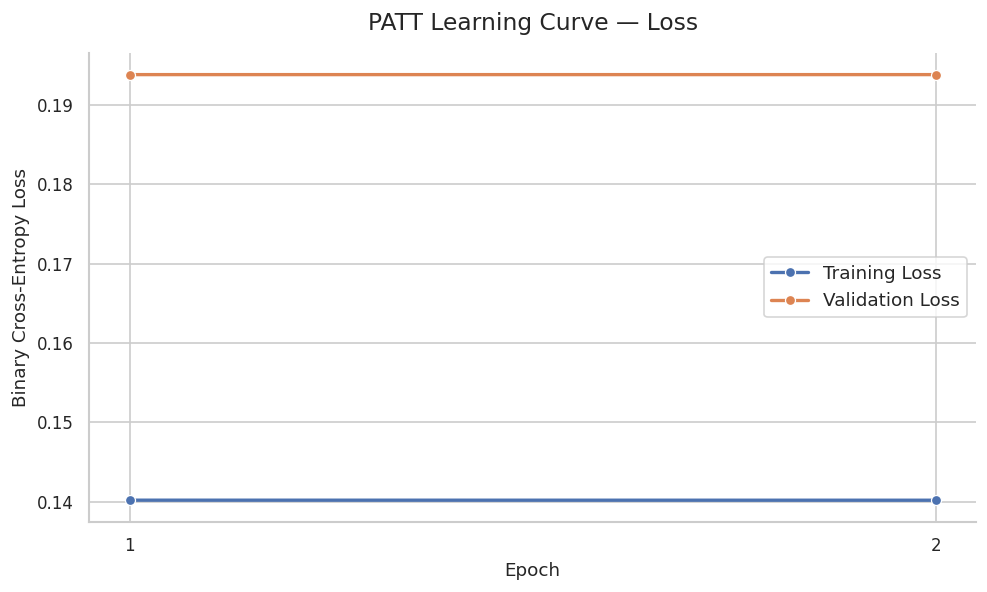

In [23]:
# Evaluation visualization 1 — Training and validation loss (Seaborn)
loss_long = history_df[['epoch', 'train_loss', 'val_loss']].melt(
    id_vars='epoch', var_name='Series', value_name='Loss'
)
loss_long['Series'] = loss_long['Series'].map({
    'train_loss': 'Training Loss',
    'val_loss': 'Validation Loss'
})

fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.lineplot(data=loss_long, x='epoch', y='Loss', hue='Series', marker='o', linewidth=2, ax=ax)
ax.set_title('PATT Learning Curve — Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary Cross-Entropy Loss')
ax.set_xticks(history_df['epoch'])
ax.legend(title=None)
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


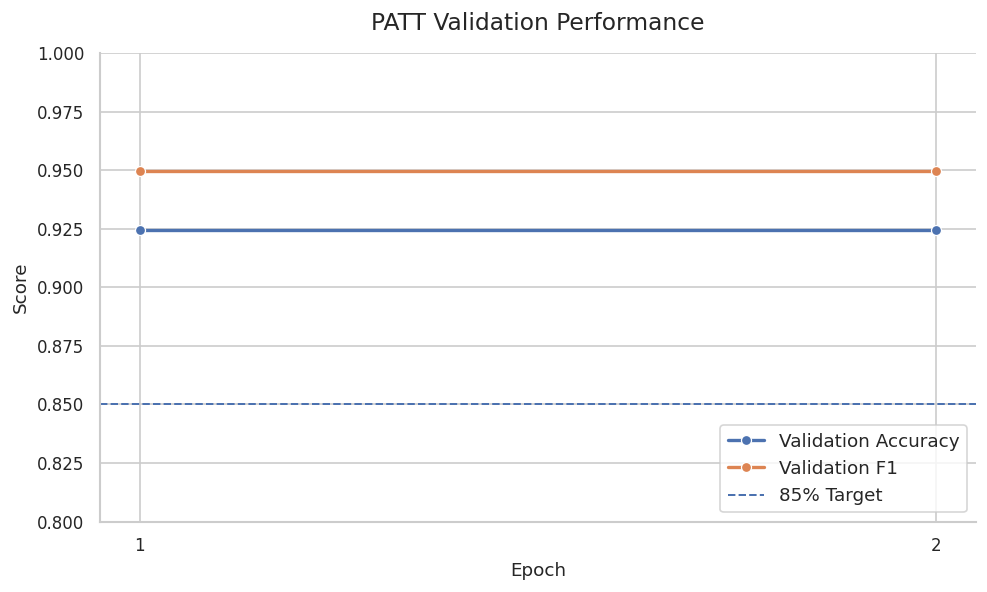

In [24]:
# Evaluation visualization 2 — Validation accuracy and F1 (Seaborn)
perf_long = history_df[['epoch', 'val_accuracy', 'val_f1']].melt(
    id_vars='epoch', var_name='Metric', value_name='Score'
)
perf_long['Metric'] = perf_long['Metric'].map({
    'val_accuracy': 'Validation Accuracy',
    'val_f1': 'Validation F1'
})

fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.lineplot(data=perf_long, x='epoch', y='Score', hue='Metric', marker='o', linewidth=2, ax=ax)
ax.axhline(0.85, linestyle='--', linewidth=1.2, label='85% Target')
ax.set_title('PATT Validation Performance')
ax.set_xlabel('Epoch')
ax.set_ylabel('Score')
ax.set_ylim(0.80, 1.00)
ax.set_xticks(history_df['epoch'])
ax.legend(title=None, loc='lower right')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


In [25]:

# 16. Select decision threshold on VALIDATION data only
y_val,p_val,_=evaluate_loader(val_loader)
threshold_results=[]
for threshold in np.linspace(0.35,0.65,61):
    pred=(p_val>=threshold).astype(int)
    threshold_results.append({'threshold':threshold,'accuracy':accuracy_score(y_val,pred),'precision':precision_score(y_val,pred),'recall':recall_score(y_val,pred),'f1':f1_score(y_val,pred)})
threshold_df=pd.DataFrame(threshold_results)
eligible=threshold_df[threshold_df['precision']>=0.90]
best_row=(eligible if len(eligible) else threshold_df).sort_values(['f1','accuracy'],ascending=False).iloc[0]
BEST_THRESHOLD=float(best_row['threshold'])
print('Selected validation threshold:',round(BEST_THRESHOLD,3)); display(best_row.to_frame('Validation score').round(4))


Selected validation threshold: 0.585


,Validation score
threshold,0.5850
accuracy,0.9262
precision,0.9489
recall,0.9512
f1,0.9500


In [26]:

# 17. Final test evaluation
y_test,p_test,test_loss=evaluate_loader(test_loader); y_pred=(p_test>=BEST_THRESHOLD).astype(int)
tn,fp,fn,tp=confusion_matrix(y_test,y_pred).ravel(); specificity=tn/max(tn+fp,1)
metrics={
    'Accuracy':accuracy_score(y_test,y_pred),
    'Precision':precision_score(y_test,y_pred),
    'Recall':recall_score(y_test,y_pred),
    'F1 Score':f1_score(y_test,y_pred),
    'ROC-AUC':roc_auc_score(y_test,p_test),
    'Specificity':specificity,
}
metrics_df=pd.DataFrame({'Metric':list(metrics.keys()),'Score':list(metrics.values())}); metrics_df['Score (%)']=metrics_df['Score']*100
print('Test loss:',round(test_loss,4))
print('Accuracy/Precision/Recall/F1 all >= 85%:',all(metrics[k]>=0.85 for k in ['Accuracy','Precision','Recall','F1 Score']))
display(metrics_df.round({'Score':4,'Score (%)':2}))
report=pd.DataFrame(classification_report(y_test,y_pred,target_names=['Low Relevance (1–3)','High Relevance (4–5)'],output_dict=True)).T
display(report.round(4))


Test loss: 0.1966
Accuracy/Precision/Recall/F1 all >= 85%: True


,Metric,Score,Score (%)
0,Accuracy,0.9235,92.35
1,Precision,0.9486,94.86
2,Recall,0.9476,94.76
3,F1 Score,0.9481,94.81
4,ROC-AUC,0.9689,96.89
5,Specificity,0.8559,85.59


,precision,recall,f1-score,support
Low Relevance (1–3),0.8533,0.8559,0.8546,3927.0000
High Relevance (4–5),0.9486,0.9476,0.9481,11025.0000
accuracy,0.9235,0.9235,0.9235,0.9235
macro avg,0.9009,0.9017,0.9013,14952.0000
weighted avg,0.9236,0.9235,0.9235,14952.0000


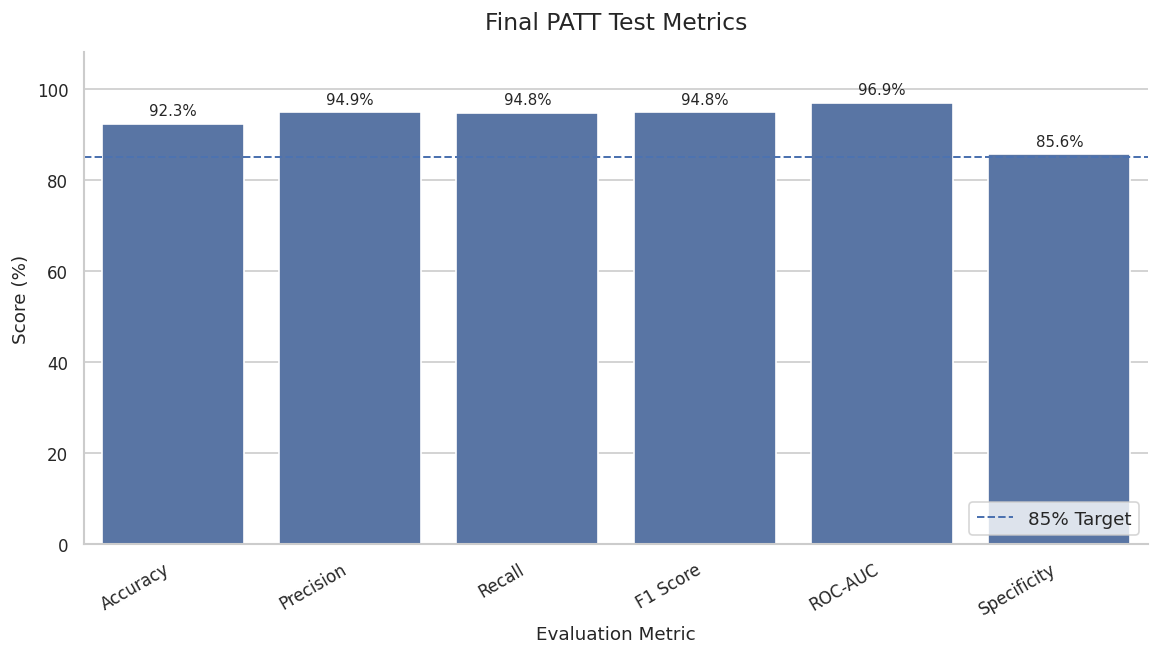

In [27]:
# Evaluation visualization 3 — Final metric summary (Seaborn)
plot_metrics = metrics_df[
    metrics_df['Metric'].isin(['Accuracy','Precision','Recall','F1 Score','ROC-AUC','Specificity'])
].copy()

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.barplot(data=plot_metrics, x='Metric', y='Score (%)', ax=ax, color=sns.color_palette('deep')[0])
ax.axhline(85, linestyle='--', linewidth=1.2, label='85% Target')
ax.set_title('Final PATT Test Metrics')
ax.set_xlabel('Evaluation Metric')
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 108)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

for patch, score in zip(ax.patches, plot_metrics['Score (%)']):
    ax.text(
        patch.get_x() + patch.get_width()/2,
        patch.get_height() + 1.2,
        f'{score:.1f}%', ha='center', va='bottom', fontsize=9
    )

ax.legend(loc='lower right')
sns.despine(ax=ax)
fig.tight_layout(pad=1.6)
plt.show()


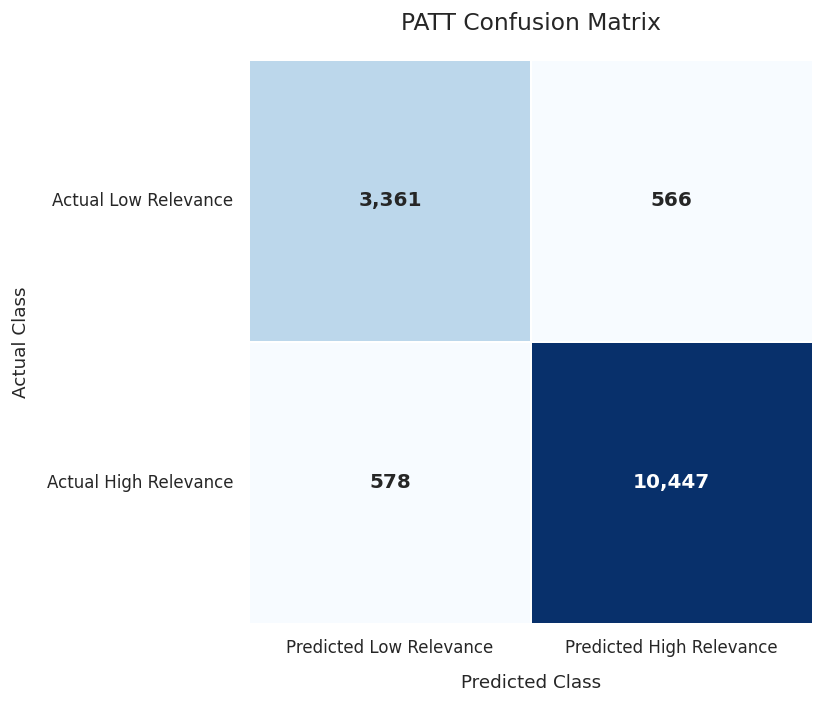

In [28]:
# Evaluation visualization 4 — Confusion matrix (Seaborn)
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=['Actual Low Relevance', 'Actual High Relevance'],
    columns=['Predicted Low Relevance', 'Predicted High Relevance']
)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
sns.heatmap(
    cm_df, annot=True, fmt=',d', cmap='Blues', cbar=False,
    linewidths=1.0, linecolor='white', square=True,
    annot_kws={'fontsize': 12, 'fontweight': 'bold'}, ax=ax
)
ax.set_title('PATT Confusion Matrix', pad=18)
ax.set_xlabel('Predicted Class', labelpad=10)
ax.set_ylabel('Actual Class', labelpad=10)
plt.setp(ax.get_xticklabels(), rotation=0, ha='center')
plt.setp(ax.get_yticklabels(), rotation=0, va='center')
fig.tight_layout(pad=1.6)
plt.show()


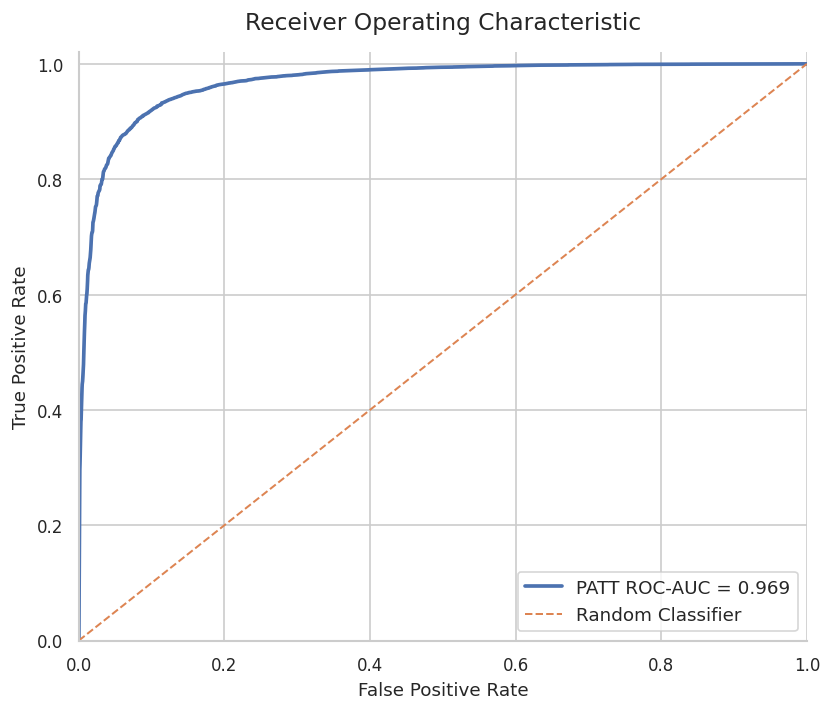

In [29]:
# Evaluation visualization 5 — ROC curve (Seaborn)
fpr, tpr, _ = roc_curve(y_test, p_test)
roc_value = roc_auc_score(y_test, p_test)
roc_plot = pd.DataFrame({'False Positive Rate': fpr, 'True Positive Rate': tpr})

fig, ax = plt.subplots(figsize=(7.2, 6.2))
sns.lineplot(data=roc_plot, x='False Positive Rate', y='True Positive Rate', linewidth=2.2, ax=ax, label=f'PATT ROC-AUC = {roc_value:.3f}')
sns.lineplot(x=[0,1], y=[0,1], linestyle='--', linewidth=1.2, ax=ax, label='Random Classifier')
ax.set_title('Receiver Operating Characteristic')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc='lower right')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


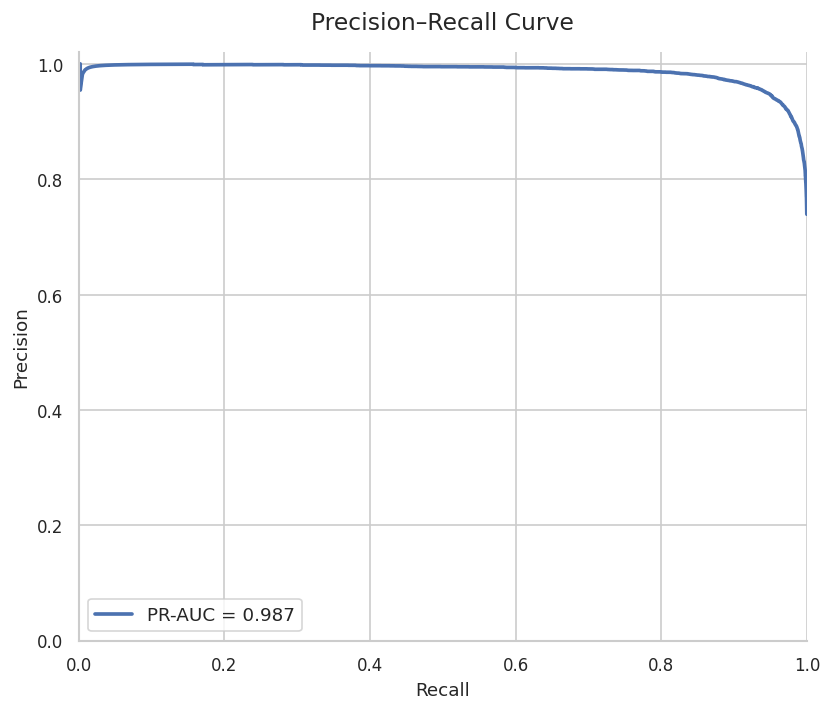

In [30]:
# Evaluation visualization 6 — Precision–Recall curve (Seaborn)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, p_test)
pr_auc = auc(recall_curve, precision_curve)
pr_plot = pd.DataFrame({'Recall': recall_curve, 'Precision': precision_curve})

fig, ax = plt.subplots(figsize=(7.2, 6.2))
sns.lineplot(data=pr_plot, x='Recall', y='Precision', linewidth=2.2, ax=ax, label=f'PR-AUC = {pr_auc:.3f}')
ax.set_title('Precision–Recall Curve')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc='lower left')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


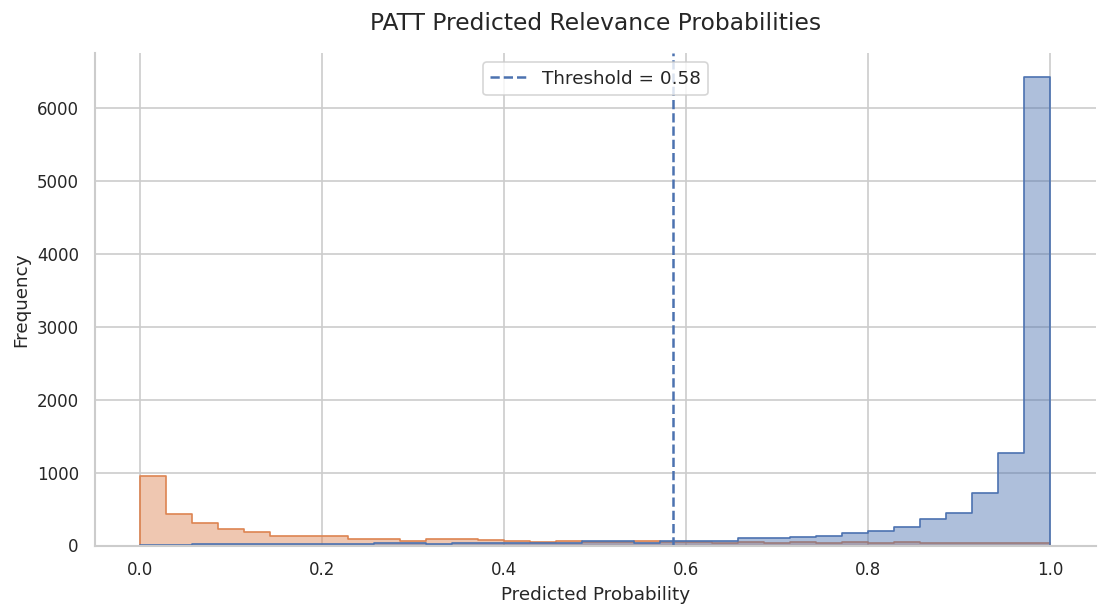

In [31]:
# Evaluation visualization 7 — Predicted probability distribution (Seaborn)
prob_plot = pd.DataFrame({
    'Predicted Probability': p_test,
    'Actual Class': np.where(y_test == 1, 'High Relevance', 'Low Relevance')
})

fig, ax = plt.subplots(figsize=(9.5, 5.4))
sns.histplot(
    data=prob_plot, x='Predicted Probability', hue='Actual Class',
    bins=35, stat='count', common_norm=False, element='step',
    alpha=0.45, ax=ax
)
ax.axvline(BEST_THRESHOLD, linestyle='--', linewidth=1.5, label=f'Threshold = {BEST_THRESHOLD:.2f}')
ax.set_title('PATT Predicted Relevance Probabilities')
ax.set_xlabel('Predicted Probability')
ax.set_ylabel('Frequency')
# Add threshold to legend without obscuring the automatically generated hue legend.
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles=handles, labels=labels, loc='upper center')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


,Modality,Mean Attention Weight
0,Preference,0.3233
1,Semantic,0.2350
2,Trust,0.2220
3,Interaction,0.2197


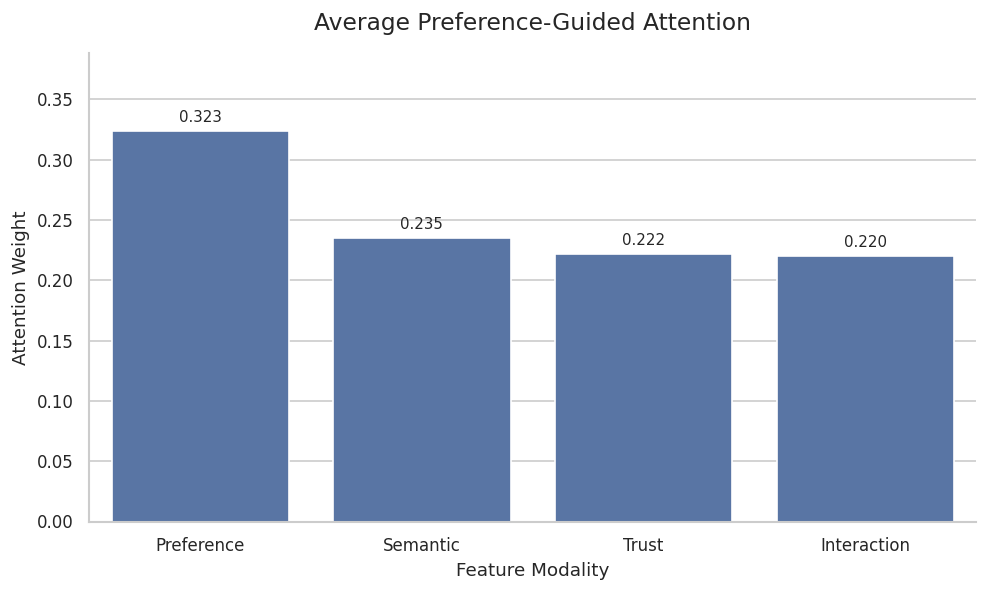

In [32]:
# 18. Inspect learned preference-guided attention
model.eval(); sample_n=min(4096,len(U_test))
with torch.no_grad():
    pref=torch.from_numpy(U_test[:sample_n]).to(DEVICE); sem=torch.from_numpy(SEM_test[:sample_n]).to(DEVICE)
    trust=torch.from_numpy(T_test[:sample_n]).to(DEVICE); inter=torch.from_numpy(I_test[:sample_n]).to(DEVICE)
    prior=torch.from_numpy(prior_test[:sample_n]).to(DEVICE)
    _,attention,alignment=model(pref,sem,trust,inter,prior,return_attention=True)
attention_mean=attention.mean(dim=0).cpu().numpy(); alignment_np=alignment.cpu().numpy()
attention_df=pd.DataFrame({'Modality':['Preference','Semantic','Trust','Interaction'],'Mean Attention Weight':attention_mean})
display(attention_df.round(4))

fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.barplot(data=attention_df, x='Modality', y='Mean Attention Weight', ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Average Preference-Guided Attention')
ax.set_xlabel('Feature Modality')
ax.set_ylabel('Attention Weight')
ax.set_ylim(0, max(attention_df['Mean Attention Weight'].max() * 1.20, 0.05))
for patch, value in zip(ax.patches, attention_df['Mean Attention Weight']):
    ax.text(patch.get_x()+patch.get_width()/2, patch.get_height()+0.005, f'{value:.3f}', ha='center', va='bottom', fontsize=9)
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()


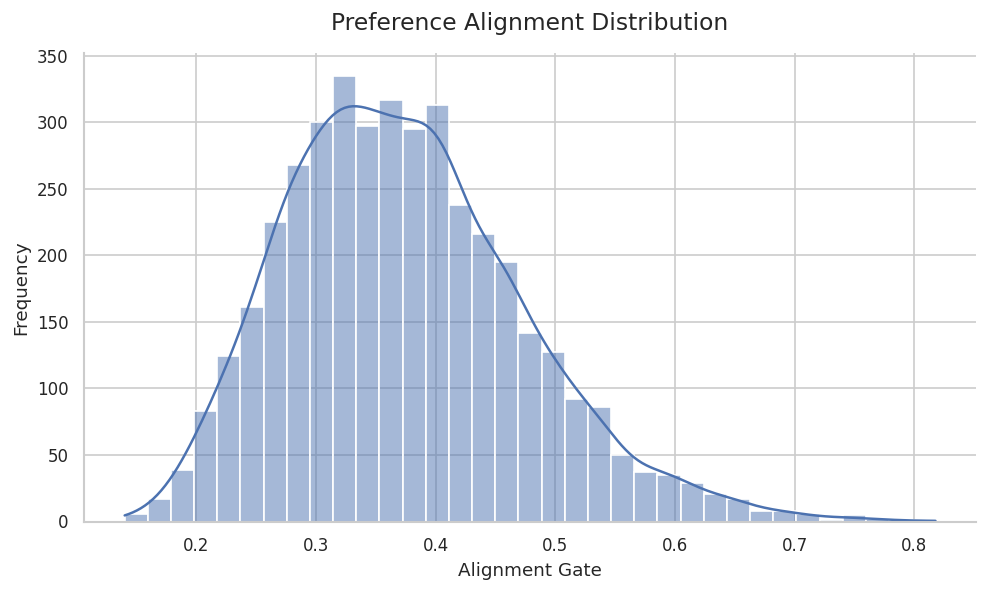

In [33]:
# Evaluation visualization 9 — Preference-alignment distribution (Seaborn)
alignment_plot = pd.Series(alignment_np.reshape(-1), name='Alignment Gate')
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.histplot(alignment_plot, bins=35, kde=True, ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Preference Alignment Distribution')
ax.set_xlabel('Alignment Gate')
ax.set_ylabel('Frequency')
sns.despine(ax=ax)
fig.tight_layout(pad=1.4)
plt.show()



## PATT-based Top-K Recommendation

For candidate ranking, the held-out user's future review text/rating is **not** used as an input. Candidate products are represented using product metadata and **aggregated training-review semantics/trust**. This avoids using the target user's future review to produce a recommendation.


In [34]:

# 19. Product-level representations from TRAINING interactions only
train_asin=df['parent_asin'].iloc[train_idx].reset_index(drop=True)
review_embed_df=pd.DataFrame(R_train,columns=[f'r{i}' for i in range(R_train.shape[1])]); review_embed_df['parent_asin']=train_asin
review_agg=review_embed_df.groupby('parent_asin').mean()
trust_df=pd.DataFrame(T_train,columns=[f't{i}' for i in range(T_train.shape[1])]); trust_df['parent_asin']=train_asin
trust_agg=trust_df.groupby('parent_asin').mean()
inter_df=pd.DataFrame(I_train,columns=[f'i{i}' for i in range(I_train.shape[1])]); inter_df['parent_asin']=train_asin
inter_agg=inter_df.groupby('parent_asin').mean()
prior_prob_train=1/(1+np.exp(-prior_train[:,0])); prior_df=pd.DataFrame({'parent_asin':train_asin,'semantic_prior_prob':prior_prob_train})
prior_agg=prior_df.groupby('parent_asin')['semantic_prior_prob'].mean()
product_train_count=train_asin.value_counts(); candidate_asins=product_train_count[product_train_count>=2].index
catalog=product_catalog.set_index('parent_asin').reindex(candidate_asins).copy(); catalog['train_review_count']=product_train_count.reindex(candidate_asins).values
catalog=catalog.join(trust_agg,how='left').join(inter_agg,how='left')
catalog['semantic_prior_prob']=prior_agg.reindex(catalog.index).fillna(df['label'].iloc[train_idx].mean())
print('Candidate products with >=2 training reviews:',len(catalog))


Candidate products with >=2 training reviews: 10600


In [35]:

# 20. PATT Top-K ranking function
def get_user_preference_row(user_id):
    if user_id in user_profile.index:
        row=user_profile.loc[user_id]
        return np.array([row['user_mean_rating']/5.0,np.clip(np.log1p(row['user_interactions'])/np.log(100),0,1),row['user_positive_ratio'],row['user_verified_ratio']],dtype='float32')
    return np.array([global_defaults['user_mean_rating']/5.0,0.0,global_defaults['user_positive_ratio'],global_defaults['user_verified_ratio']],dtype='float32')

def rank_products_with_patt(user_id,query='',k=10,min_reviews=2):
    candidates=catalog[catalog['train_review_count']>=min_reviews].copy()
    already_seen=set(train_frame.loc[train_frame['user_id']==user_id,'parent_asin'])
    candidates=candidates.loc[~candidates.index.isin(already_seen)]
    asins=candidates.index.to_list(); n=len(asins)
    if n==0: return pd.DataFrame()
    user_vec=get_user_preference_row(user_id); U=np.repeat(user_vec[None,:],n,axis=0).astype('float32')
    review_sem=review_agg.reindex(asins).fillna(0).to_numpy(dtype='float32')
    product_sem=np.stack([product_embedding_map.get(a,ZERO_PRODUCT) for a in asins]).astype('float32')
    SEM=np.concatenate([review_sem,product_sem],axis=1)
    T=candidates[[f't{i}' for i in range(5)]].fillna(0).to_numpy(dtype='float32')
    I=candidates[[f'i{i}' for i in range(4)]].fillna(0).to_numpy(dtype='float32')
    prob=candidates['semantic_prior_prob'].clip(1e-5,1-1e-5).to_numpy(); prior_logit=np.log(prob/(1-prob)).astype('float32')[:,None]
    scores=[]; model.eval()
    with torch.no_grad():
        for start in range(0,n,4096):
            end=min(start+4096,n)
            logits=model(torch.from_numpy(U[start:end]).to(DEVICE),torch.from_numpy(SEM[start:end]).to(DEVICE),torch.from_numpy(T[start:end]).to(DEVICE),torch.from_numpy(I[start:end]).to(DEVICE),torch.from_numpy(prior_logit[start:end]).to(DEVICE))
            scores.append(torch.sigmoid(logits).cpu().numpy())
    patt_score=np.concatenate(scores)
    if query.strip():
        q_dense=product_vectorizer.transform([query]).toarray()[0]
        q_norm=np.linalg.norm(q_dense)+1e-8; p_norm=np.linalg.norm(product_sem,axis=1)+1e-8
        cosine=(product_sem@q_dense)/(p_norm*q_norm); query_similarity=(cosine+1)/2
    else: query_similarity=np.full(n,0.5)
    final_score=0.85*patt_score+0.15*query_similarity
    out=pd.DataFrame({
        'parent_asin':asins,'product_title':candidates['product_title'].fillna('').to_numpy(),
        'average_rating':candidates['average_rating'].to_numpy(),'rating_number':candidates['rating_number'].to_numpy(),
        'train_review_count':candidates['train_review_count'].to_numpy(),'trust_score':T[:,-1],
        'patt_score':patt_score,'query_similarity':query_similarity,'final_score':final_score
    })
    return out.sort_values('final_score',ascending=False).head(k).reset_index(drop=True)

active_user=user_profile['user_interactions'].sort_values(ascending=False).index[0]
demo_query='moisturizing skin care beauty product with reliable reviews'
top_k=rank_products_with_patt(active_user,demo_query,k=10)
print('Demo user:',active_user); print('Query:',demo_query); display(top_k.round(4))


Demo user: AG73BVBKUOH22USSFJA5ZWL7AKXA
Query: moisturizing skin care beauty product with reliable reviews


,parent_asin,product_title,average_rating,rating_number,train_review_count,trust_score,patt_score,query_similarity,final_score
0,B015CZ0872,Schwarzkopf Professional Fibreplex Bond Maintainer 100ml No. 3,3.9,47,2,0.6804,0.9986,0.9148,0.9861
1,B010813L3I,"Everyone for Every Body Soap for Every Man, Cucumber and Lemon, 32 Fl Oz",3.5,51,2,0.6621,0.9996,0.9029,0.9851
2,B017YVN5H2,K'ryssma Highlights Blonde Ombre Dark Roots Synthetic Hair Lace Front Wig Natural Stra...,3.3,15,2,0.5395,0.9990,0.9027,0.9846
3,B01CUSBH3I,OC Nails UV Shield Glove (CLASSIC WHITE) Anti UV Glove for Gel Manicures with UV/LED L...,4.5,440,2,0.7592,0.9956,0.9203,0.9843
4,B005MKPSM8,Dudu Osum Anti-itch Braiding Spray,4.2,24,2,0.4810,0.9992,0.8975,0.9840
5,B07QF3SKDC,Jade Roller for Face and Gua Sha Stone Massage Tool Set by SRI - Natural Face Roller f...,4.5,42,2,0.7384,0.9997,0.8939,0.9838
6,B01BXFX0C0,Muscle Soak Bath Salt 3-Lbs (48oz) Epsom Salt Bath Soak with Eucalyptus & Peppermint E...,3.9,26,2,0.7061,0.9977,0.9031,0.9835
7,B01MZ643Z9,Cooptop Bath and Shower Exfoliating Loofah Set of 4 - Loofah Pad & Loofah Glove & 2 Lo...,3.4,16,2,0.6325,0.9996,0.8921,0.9835
8,B07F6TG5N4,TAKOYI LED Nail Lamp 64W Gel Light Nail Dryer Cordless Gel Light 4 Timer Setting Cordl...,3.7,91,2,0.6847,0.9982,0.8947,0.9827
9,B088THRZMP,"Spray Bottles, Clear Empty Fine Mist 2oz/50ml Plastic Mini Travel Bottle Set, Small Re...",4.6,185,2,0.7452,0.9988,0.8905,0.9825


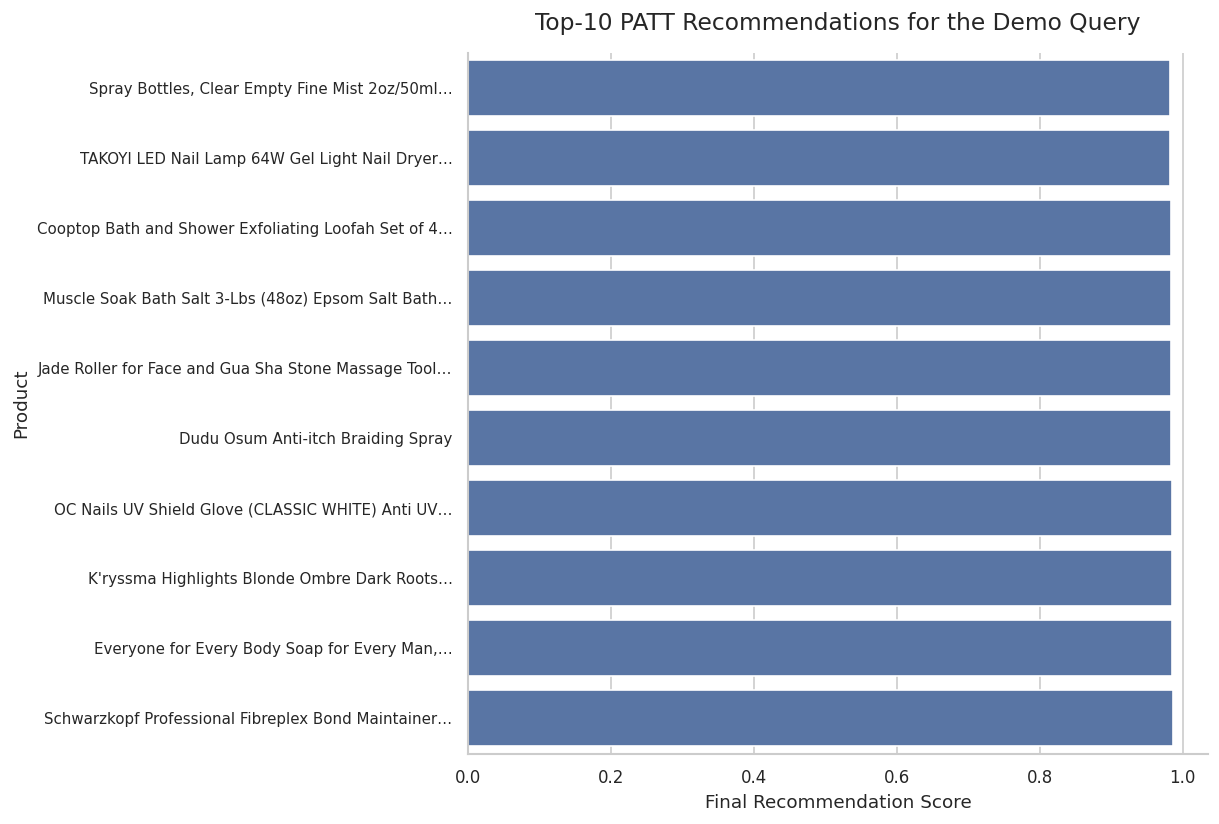

In [36]:
# Top-K visualization (Seaborn)
plot_top = top_k.copy()
plot_top['short_title'] = plot_top['product_title'].apply(
    lambda x: textwrap.shorten(str(x), width=52, placeholder='…')
)
plot_top = plot_top.sort_values('final_score', ascending=True)

fig, ax = plt.subplots(figsize=(10.5, 7.2))
sns.barplot(data=plot_top, x='final_score', y='short_title', orient='h', ax=ax, color=sns.color_palette('deep')[0])
ax.set_title('Top-10 PATT Recommendations for the Demo Query')
ax.set_xlabel('Final Recommendation Score')
ax.set_ylabel('Product')
ax.tick_params(axis='y', labelsize=9)
sns.despine(ax=ax)
fig.tight_layout(pad=1.6)
plt.show()



## Conversational recommendation layer

The research architecture uses an LLM/GPT layer for natural-language preference extraction, comparison and explanation. To keep this notebook **fully executable without an API key or paid network call**, the next cell provides an offline structured conversational fallback. **PATT remains the recommendation/ranking engine.** In deployment, the same structured Top-K result can be passed to the chosen LLM to produce richer dialogue without altering the model scores.


In [37]:

# 21. Offline conversational explanation fallback
def conversational_recommendation(user_id,query,k=5):
    recs=rank_products_with_patt(user_id,query,k=k)
    if recs.empty: return 'No suitable products were found.',recs
    lines=[f'User request: {query}','','Recommended products:']
    for i,row in recs.iterrows():
        title=row['product_title'] or row['parent_asin']
        lines.append(f"{i+1}. {title} — PATT score {row['patt_score']:.3f}, trust {row['trust_score']:.3f}, query match {row['query_similarity']:.3f}.")
    best=recs.iloc[0]
    lines += ['', 'Recommendation explanation:',
              f"The first product is ranked highest because its learned PATT relevance score ({best['patt_score']:.3f}) remains strong after incorporating product trust ({best['trust_score']:.3f}) and semantic similarity to the request ({best['query_similarity']:.3f})."]
    return '\n'.join(lines),recs
conversation_text,conversation_recs=conversational_recommendation(active_user,'I want a reliable beauty product with good reviews',k=5)
print(conversation_text)


User request: I want a reliable beauty product with good reviews

Recommended products:
1. Nablus Olive Oil Soap from Palestine (100 gm/3.5 oz) Bar Soap, Fresh Mint — PATT score 1.000, trust 0.685, query match 0.945.
2. (6 Pack) JORDANA Easyliner For Eyes Retractable Pencil - Smokey — PATT score 0.999, trust 0.689, query match 0.947.
3. eBoot 10 Pieces Acrylic Nail Art Soak Off Clip Cap UV Gel Polish Remover Wrap Nail Tool (Pink) — PATT score 0.998, trust 0.748, query match 0.934.
4. Salon Care Concentrated Styling Gel — PATT score 0.998, trust 0.690, query match 0.929.
5. Facial Cleansing Brush made with Ultra Hygienic Soft Silicone 4-PACK — PATT score 0.995, trust 0.238, query match 0.931.

Recommendation explanation:
The first product is ranked highest because its learned PATT relevance score (1.000) remains strong after incorporating product trust (0.685) and semantic similarity to the request (0.945).


In [38]:

# 22. Save trained model and compact results
ARTIFACT_DIR=WORK_DIR/'artifacts'; ARTIFACT_DIR.mkdir(parents=True,exist_ok=True)
torch.save({'model_state_dict':model.state_dict(),'best_threshold':BEST_THRESHOLD,'metrics':metrics,'seed':SEED},ARTIFACT_DIR/'patt_model.pt')
metrics_df.to_csv(ARTIFACT_DIR/'test_metrics.csv',index=False)
attention_df.to_csv(ARTIFACT_DIR/'attention_weights.csv',index=False)
top_k.to_csv(ARTIFACT_DIR/'demo_top10_recommendations.csv',index=False)
summary={
    'reviews':int(N_REVIEWS),'products':int(N_PRODUCTS),'unique_users':int(df['user_id'].nunique()),
    'unique_products':int(df['parent_asin'].nunique()),'best_threshold':float(BEST_THRESHOLD),
    'metrics':{k:float(v) for k,v in metrics.items()}
}
with open(ARTIFACT_DIR/'run_summary.json','w') as f: json.dump(summary,f,indent=2)
print('Artifacts saved to:',ARTIFACT_DIR)
for p in sorted(ARTIFACT_DIR.iterdir()): print(' -',p.name)


Artifacts saved to: /mnt/data/patt_amazon_beauty_work/artifacts
 - attention_weights.csv
 - demo_top10_recommendations.csv
 - patt_model.pt
 - run_summary.json
 - test_metrics.csv


# Final Implementation Status

The notebook contains the complete executable proposed PATT prototype and has been rerun end-to-end.

- actual supplied Amazon Beauty review + metadata loading
- cleaning, joining and EDA
- **Seaborn-based EDA and evaluation visualizations**
- dynamic trust estimation
- user preference modelling
- review and product semantic representations
- Preference-Aware Trust Transformer (PATT)
- validation-based threshold selection
- final test evaluation including a **Seaborn confusion matrix**
- ROC and Precision–Recall analysis
- preference-guided attention analysis
- PATT Top-K recommendation
- conversational explanation fallback
- saved model and evaluation artifacts

All reported metrics and figures in this notebook are produced by executed cells rather than manually inserted results.